<p align="center">
  <img src="assets/hero_kavram.svg" width="100%" alt="Gün 48 — Gradient Boosting: Hatadan Öğrenen Orman">
</p>

<p align="center">
  <img src="https://img.shields.io/badge/G%C3%BCn-48-7C3AED?style=for-the-badge" alt="Gün 48">
  <img src="https://img.shields.io/badge/Konu-Gradient_Boosting_(Kavram)-F6B84B?style=for-the-badge" alt="Konu">
  <img src="https://img.shields.io/badge/Seviye-Ba%C5%9Flang%C4%B1%C3%A7-16A34A?style=for-the-badge" alt="Seviye">
  <img src="https://img.shields.io/badge/scikit--learn-F7931E?style=for-the-badge&logo=scikit-learn&logoColor=white" alt="scikit-learn">
  <img src="https://img.shields.io/badge/Matplotlib-11557C?style=for-the-badge" alt="Matplotlib">
</p>

<table>
<tr><td width="25%" valign="top" align="center"><h3>🎯</h3><b>Soru</b><br><br>Küçük ve basit ağaçlar<br>sırayla çalışınca<br>neden bu kadar güçlü?<br><br></td><td width="25%" valign="top" align="center"><h3>📉</h3><b>Fikir</b><br><br>Her yeni ağaç<br><b>kalan hatayı</b> (artığı)<br>öğrenir<br><br></td><td width="25%" valign="top" align="center"><h3>🐢</h3><b>Sır</b><br><br>Küçük adımlar<br>(öğrenme hızı) ve<br>çok sayıda ağaç<br><br></td><td width="25%" valign="top" align="center"><h3>🎞️</h3><b>Çıktılar</b><br><br>8 grafik · 3 animasyon (GIF)<br>7 animasyonlu diyagram<br>elle hesap + sıfırdan kod<br><br></td></tr>
</table>

<table><tr><td>

<img src="assets/etiket_hedef.svg" height="34" alt="Hedefler">

**Bu dersin sonunda şunları yapabiliyor olacaksınız:**

- 💡 Gradient Boosting'in **tek cümlelik fikrini** ("her ağaç, öncekilerin kalan hatasını öğrenir") anlatmak
- 🔄 **Beş adımlık döngüyü** (ortalama → artık → küçük ağaç → küçük adımla ekle → tekrarla) sıralamak
- 🍦 8 günlük küçük bir tabloda modeli **elle** büyütmek ve her turda hatanın nasıl düştüğünü görmek
- 🏔️ "Gradient" kelimesinin neden **"yokuş aşağı inmek"** demek olduğunu sezgisel olarak kavramak
- 🐢 **Öğrenme hızı** (learning rate) ile **ağaç sayısı** arasındaki dengeyi deneyerek görmek
- ⚔️ **AdaBoost** ile farkını (satırları mı büyütür, hataları mı?) açıklamak
- 💻 Gradient Boosting'i **yaklaşık 15 satırda sıfırdan** yazıp `scikit-learn` ile birebir doğrulamak
- 🎛️ Düğmeleri (tur, hız, derinlik, rastgelelik, kayıp işlevi, erken durdurma) tanımak
- 🌀 Aynı fikrin **sınıflandırmada** (karar sınırı) nasıl çalıştığını izlemek

</td></tr></table>

<p align="center">
  <img src="assets/yol_haritasi_kavram.svg" width="100%" alt="Ders yol haritası: 12 durak">
</p>

### 🧭 Hızlı Erişim

| Durak | Bölüm | Ana soru |
|:-:|:--|:--|
| 🧰 1 | [Kurulum](#k1) | Hangi araçlarla çalışıyoruz? |
| 💡 2 | [Büyük fikir](#k2) | Küçük ağaçlar nasıl büyük başarı getirir? |
| 🔄 3 | [Beş adımlık döngü](#k3) | Algoritmanın tamamı nedir? |
| 🍦 4 | [Küçük örnek](#k4) | Dondurma satışını elle tahmin edelim |
| 🎞️ 5 | [Hata avcısı](#k5) | Model tur tur nasıl büyüyor? |
| 🏔️ 6 | [Neden "gradient"?](#k6) | Artık ile yokuş ne alaka? |
| 🐢 7 | [Öğrenme hızı](#k7) | Acele eden yanılır mı? |
| ⚔️ 8 | [AdaBoost'tan farkı](#k8) | İki boosting nasıl ayrışıyor? |
| 🧪 9 | [Sıfırdan kodlama](#k9) | 15 satırda yazabilir miyiz? |
| 🎛️ 10 | [Düğmeler](#k10) | Hangi ayar neyi değiştirir? |
| 🌀 11 | [Sınıflandırma](#k11) | Aynı fikir kategori tahmininde nasıl çalışır? |
| 🗺️ 12 | [Aile ve özet](#k12) | XGBoost, LightGBM, CatBoost nereden çıktı? Quiz ve ödevler |

<a id="k1"></a>

<p align="center">
  <img src="assets/kavram_01.svg" width="100%" alt="Bölüm 1 — Kurulum">
</p>

Kütüphaneleri ve ortak yardımcıları **tek hücrede** topluyoruz. Renkler, kayıt fonksiyonları ve rastgelelik ayarı burada; böylece her çalıştırmada **aynı sonuçları** görürüz.

In [1]:
# ── Kütüphaneler ─────────────────────────────────────────────
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Image, display
from matplotlib.animation import FuncAnimation, PillowWriter

from sklearn.datasets import load_diabetes, make_moons
from sklearn.ensemble import AdaBoostRegressor, GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.metrics import accuracy_score, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore", category=FutureWarning)

# ── Sabitler ve klasörler ───────────────────────────────────
RANDOM_STATE = 42
FIG_DIR = Path("outputs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ── Görsel tema (notebook boyunca aynı renkler) ──────────────
RENK = {"altin": "#EDAE49", "mor": "#6C5CE7", "pembe": "#D1495B", "mavi": "#2B6CB0",
        "yesil": "#2E9E6B", "turuncu": "#E8833A", "gri": "#8A94A6", "koyu": "#2E4057"}

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
})


def kaydet(fig, ad):
    """Grafiği outputs/figures altına PNG olarak kaydeder."""
    yol = FIG_DIR / f"{ad}.png"
    fig.savefig(yol)
    print(f"💾 Kaydedildi → {yol.as_posix()}")


def gif_kaydet(kare_ciz, n_kare, yol, figsize=(7, 4), fps=8, dpi=80):
    """kare_ciz(fig, i) fonksiyonuyla her kareyi çizip animasyonlu GIF olarak kaydeder."""
    fig = plt.figure(figsize=figsize)
    anim = FuncAnimation(fig, lambda i: kare_ciz(fig, i), frames=n_kare)
    anim.save(yol, writer=PillowWriter(fps=fps), dpi=dpi)
    plt.close(fig)
    print(f"💾 Animasyon → {Path(yol).as_posix()} ({Path(yol).stat().st_size / 1024:.0f} KB)")


print(f"scikit-learn {sklearn.__version__} · pandas {pd.__version__} · numpy {np.__version__}")

scikit-learn 1.9.1 · pandas 3.0.5 · numpy 2.5.3


<a id="k2"></a>

<p align="center">
  <img src="assets/kavram_02.svg" width="100%" alt="Bölüm 2 — Büyük Fikir">
</p>

Golf oynayan birini düşünün. Topu **tek vuruşta** deliğe sokmak neredeyse imkânsızdır. Ama her vuruşta yalnızca **"delik hâlâ ne kadar uzakta?"** diye bakarsanız ve kalan mesafenin bir kısmını kapatırsanız, birkaç vuruşta deliğe yaklaşırsınız.

<p align="center">
  <img src="assets/diyagram_golf.svg" width="100%" alt="Golf benzetmesi">
</p>

**Gradient Boosting** (*Gradient Artırma*) aynen böyle çalışır:

1. İlk tahmin kabadır (örneğin hep ortalama).
2. Her satırda **ne kadar yanıldığımıza** (kalan hataya) bakılır.
3. Küçük bir ağaç, **yalnızca bu kalan hatayı** tahmin etmeyi öğrenir.
4. Ağacın düzeltmesi tahmine **küçük bir adımla** eklenir.
5. Yeni kalan hataya bakılır ve süreç tekrarlanır.

Sonuçta nihai tahmin, **bir ortalama + yüzlerce küçük düzeltmenin toplamıdır**:

<p align="center">
  <img src="assets/diyagram_takim.svg" width="100%" alt="Tahmin bir toplamdır">
</p>

### 🧪 2.1 · Önce Sonucu Görelim

Aşağıda gürültülü bir eğri var (gerçek örüntü + rastgele sapmalar). Üç model yarışıyor: **tek kütük** (1 soru), **tek küçük ağaç** (2 soru) ve **100 küçük ağacın** Gradient Boosting ekibi. Hepsi aynı veriyle eğitiliyor, sonra **hiç görmedikleri 400 yeni noktada** sınanıyor.

Hep ortalamayı söyleyen model MAE : 1.78
Ulaşılabilecek en iyi MAE (gürültü tabanı): ≈ 0.64


💾 Kaydedildi → outputs/figures/kavram_01_tek_model_mi_ekip_mi.png


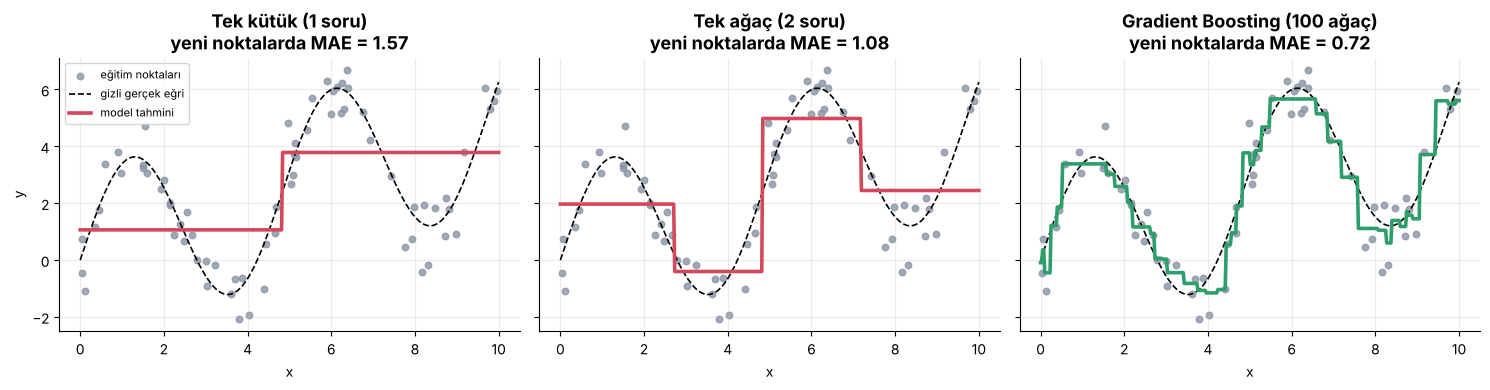

In [2]:
def gercek(x):
    """Gizli örüntü: dalgalı ve yükselen bir eğri (model bunu bilmiyor)."""
    return 3 * np.sin(1.3 * x) + 0.5 * x


rng = np.random.default_rng(7)
x_e = np.sort(rng.uniform(0, 10, 70));  y_e = gercek(x_e) + rng.normal(0, 0.8, 70)       # eğitim: 70 gürültülü nokta
x_t = rng.uniform(0, 10, 400);          y_t = gercek(x_t) + rng.normal(0, 0.8, 400)      # test: 400 yeni gürültülü nokta
X_e, X_t = x_e.reshape(-1, 1), x_t.reshape(-1, 1)
xs = np.linspace(0, 10, 400).reshape(-1, 1)                                               # çizim ızgarası

GURULTU_TABANI = 0.8 * np.sqrt(2 / np.pi)       # σ=0.8 gürültüde, gerçek eğriyi bilen kusursuz modelin bile MAE'si
print(f"Hep ortalamayı söyleyen model MAE : {mean_absolute_error(y_t, np.full(len(y_t), y_e.mean())):.2f}")
print(f"Ulaşılabilecek en iyi MAE (gürültü tabanı): ≈ {GURULTU_TABANI:.2f}")

modeller = {
    "Tek kütük (1 soru)":              DecisionTreeRegressor(max_depth=1, random_state=RANDOM_STATE),
    "Tek ağaç (2 soru)":               DecisionTreeRegressor(max_depth=2, random_state=RANDOM_STATE),
    "Gradient Boosting (100 ağaç)":    GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=2, random_state=RANDOM_STATE),
}
fig, eksenler = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (ad, m) in zip(eksenler, modeller.items()):
    m.fit(X_e, y_e)
    hata = mean_absolute_error(y_t, m.predict(X_t))
    ax.scatter(x_e, y_e, s=22, color=RENK["gri"], alpha=0.8, label="eğitim noktaları")
    ax.plot(xs, gercek(xs), color="black", lw=1.2, ls="--", label="gizli gerçek eğri")
    ax.plot(xs, m.predict(xs), color=RENK["pembe"] if "Boosting" not in ad else RENK["yesil"], lw=2.6, label="model tahmini")
    ax.set_title(f"{ad}\nyeni noktalarda MAE = {hata:.2f}")
    ax.set_xlabel("x")
eksenler[0].set_ylabel("y")
eksenler[0].legend(loc="upper left", fontsize=8)
fig.tight_layout()
kaydet(fig, "kavram_01_tek_model_mi_ekip_mi")
plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

**Tek kütük** yalnızca bir eşik koyabilir; **tek küçük ağaç** dört basamak çizebilir. **100 küçük ağaç** ise sırayla birbirinin hatasını düzelterek **kıvrımlı bir eğriyi** yakalar. Hiçbir ağaç tek başına güçlü değil; **güç, sıranın ve küçük düzeltmelerin toplamından** geliyor.

</td></tr></table>

<a id="k3"></a>

<p align="center">
  <img src="assets/kavram_03.svg" width="100%" alt="Bölüm 3 — Beş Adımlık Döngü">
</p>

Gradient Boosting'in tamamı **beş adımdan** ibarettir. Döngü her dönüşünde modele **bir küçük ağaç** ekler:

<p align="center">
  <img src="assets/diyagram_dongu.svg" width="100%" alt="Gradient Boosting döngüsü">
</p>

### 🪜 3.1 · Beş Adımın Sade Anlatımı

| Adım | Ne yapılır? | Gündelik benzetme |
|:-:|:--|:--|
| 1️⃣ | **Başlangıç tahmini:** herkese aynı sayı (hedefin ortalaması) | "Bu dükkânın günlük satışı ortalama ne kadar? Herkese onu söyle." |
| 2️⃣ | **Kalan hata (artık):** $\text{artık} = \text{gerçek} - \text{tahmin}$ | "Ortalamayla gerçek arasındaki fark ne kadar?" |
| 3️⃣ | **Küçük ağaç eğit:** ağacın hedefi gerçek değil, **artıktır** | "Sıcak günlerde ortalamadan fazla, soğuk günlerde az satılıyor; bunu öğren." |
| 4️⃣ | **Güncelle:** $\text{tahmin} \leftarrow \text{tahmin} + \eta \cdot \text{ağaç}$ | "Öğrendiğin düzeltmenin yarısını (veya onda birini) uygula, aşırıya kaçma." |
| 5️⃣ | **Tekrarla:** yeni artık hesapla, yeni ağaç ekle | "Hâlâ yanıldığımız yerlere bak, onları da düzelt." |

$\eta$ (eta) harfi **öğrenme hızıdır**: her ağacın düzeltmesinden ne kadarını aldığımızı söyler (1 = tamamını, 0,1 = onda birini).

<table><tr><td>

<img src="assets/etiket_kavram.svg" height="34" alt="Kavram">

**Neden "artığı" öğreniyoruz?** Çünkü ağaç zaten doğru olan yerlerde bir şey yapmasa da olur; ona yalnızca **hâlâ yanlış olan kısmı** veriyoruz. Her tur, problemi biraz daha **küçültür**: önce büyük hatalar, sonra ince ayrıntılar. Bu yüzden her ağacın **küçük** (3–8 yapraklı) olması yeterlidir.

</td></tr></table>

<a id="k4"></a>

<p align="center">
  <img src="assets/kavram_04.svg" width="100%" alt="Bölüm 4 — Küçük Örnek">
</p>

Bir dondurmacı, **sıcaklığa göre günlük satışı** tahmin etmek istiyor. Elimizde yalnızca **8 günlük** (özgün, uydurma ama gerçekçi) bir tablo var. Küçük olduğu için her adımı **elle** takip edebiliriz.

In [3]:
dondurma = pd.DataFrame({"Sıcaklık (°C)": [14, 17, 20, 23, 26, 29, 32, 35],
                         "Satış (adet)":  [20, 28, 35, 55, 72, 90, 95, 98]},
                        index=pd.RangeIndex(1, 9, name="Gün"))
X_d = dondurma[["Sıcaklık (°C)"]].to_numpy(dtype=float)      # (8, 1) boyutlu özellik matrisi
y_d = dondurma["Satış (adet)"].to_numpy(dtype=float)
dondurma

,Sıcaklık (°C),Satış (adet)
Gün,,
1,14,20
2,17,28
3,20,35
4,23,55
5,26,72
6,29,90
7,32,95
8,35,98


### 🎯 4.1 · Adım 1: Başlangıç Tahmini = Ortalama

En basit tahmin, **tüm günler için ortalama satışı** söylemektir. Her gün için hata (artık) = gerçek − tahmin.

In [4]:
ETA = 0.5                                              # öğrenme hızı (örnekte büyük tuttuk ki etkiyi hemen görelim)
F0 = np.full(len(y_d), y_d.mean())                     # adım 1: herkese ortalama
artik0 = y_d - F0                                      # adım 2: kalan hata

tablo0 = dondurma.assign(**{"Tahmin (ortalama)": F0.round(1), "Artık = gerçek − tahmin": artik0.round(1)})
display(tablo0)
print(f"Ortalama satış = {y_d.mean():.1f} adet   →   ortalama mutlak hata (MAE) = {np.abs(artik0).mean():.2f}")

,Sıcaklık (°C),Satış (adet),Tahmin (ortalama),Artık = gerçek − tahmin
Gün,,,,
1,14,20,61.6,-41.6
2,17,28,61.6,-33.6
3,20,35,61.6,-26.6
4,23,55,61.6,-6.6
5,26,72,61.6,10.4
6,29,90,61.6,28.4
7,32,95,61.6,33.4
8,35,98,61.6,36.4


Ortalama satış = 61.6 adet   →   ortalama mutlak hata (MAE) = 27.12


### 🌳 4.2 · Adım 3 ve 4: Küçük Ağaç Artıkları Öğrenir, Tahmine Eklenir

Şimdi **yalnızca 1 soru soran** bir ağaç (kütük) eğitiyoruz; ama hedefi satışlar **değil artıklardır**. Ardından düzeltmesini $\eta = 0{,}5$ ile çarpıp tahmine ekliyoruz. Bu döngüyü **3 tur** döndürüp her turun sonucunu yazdırıyoruz:

In [5]:
F = F0.copy()                                           # güncel tahmin
turlar = []                                             # her turun ayrıntısını sakla (grafik ve tablo için)

for tur in range(1, 4):
    artik = y_d - F                                     # adım 2: kalan hata
    agac = DecisionTreeRegressor(max_depth=1, random_state=RANDOM_STATE).fit(X_d, artik)      # adım 3: artığı öğren
    duzeltme = agac.predict(X_d)                        # ağacın önerdiği düzeltme
    F_yeni = F + ETA * duzeltme                         # adım 4: küçük adımla ekle
    esik = agac.tree_.threshold[0]
    sol, sag = agac.tree_.value[1].item(), agac.tree_.value[2].item()
    turlar.append({"tur": tur, "F_once": F.copy(), "artik": artik, "duzeltme": duzeltme, "F_sonra": F_yeni.copy(), "esik": esik})

    print(f"━━━ TUR {tur} ━━━  Ağacın kuralı: sıcaklık ≤ {esik:.1f} °C ise düzeltme {sol:+.1f}, değilse {sag:+.1f}")
    display(dondurma[["Satış (adet)"]].assign(**{"Tahmin (önce)": F.round(1), "Artık": artik.round(1),
                                                  "Ağaç düzeltmesi": duzeltme.round(1),
                                                  f"Yeni tahmin (+{ETA}×düzeltme)": F_yeni.round(1)}))
    print(f"    MAE: {np.abs(y_d - F).mean():.2f}  →  {np.abs(y_d - F_yeni).mean():.2f}\n")
    F = F_yeni

━━━ TUR 1 ━━━  Ağacın kuralı: sıcaklık ≤ 24.5 °C ise düzeltme -27.1, değilse +27.1


,Satış (adet),Tahmin (önce),Artık,Ağaç düzeltmesi,Yeni tahmin (+0.5×düzeltme)
Gün,,,,,
1,20,61.6,-41.6,-27.1,48.1
2,28,61.6,-33.6,-27.1,48.1
3,35,61.6,-26.6,-27.1,48.1
4,55,61.6,-6.6,-27.1,48.1
5,72,61.6,10.4,27.1,75.2
6,90,61.6,28.4,27.1,75.2
7,95,61.6,33.4,27.1,75.2
8,98,61.6,36.4,27.1,75.2


    MAE: 27.12  →  16.09

━━━ TUR 2 ━━━  Ağacın kuralı: sıcaklık ≤ 21.5 °C ise düzeltme -20.4, değilse +12.2


,Satış (adet),Tahmin (önce),Artık,Ağaç düzeltmesi,Yeni tahmin (+0.5×düzeltme)
Gün,,,,,
1,20,48.1,-28.1,-20.4,37.9
2,28,48.1,-20.1,-20.4,37.9
3,35,48.1,-13.1,-20.4,37.9
4,55,48.1,6.9,12.2,54.2
5,72,75.2,-3.2,12.2,81.3
6,90,75.2,14.8,12.2,81.3
7,95,75.2,19.8,12.2,81.3
8,98,75.2,22.8,12.2,81.3


    MAE: 16.09  →  9.97

━━━ TUR 3 ━━━  Ağacın kuralı: sıcaklık ≤ 27.5 °C ise düzeltme -7.8, değilse +13.0


,Satış (adet),Tahmin (önce),Artık,Ağaç düzeltmesi,Yeni tahmin (+0.5×düzeltme)
Gün,,,,,
1,20,37.9,-17.9,-7.8,34.0
2,28,37.9,-9.9,-7.8,34.0
3,35,37.9,-2.9,-7.8,34.0
4,55,54.2,0.8,-7.8,50.3
5,72,81.3,-9.3,-7.8,77.4
6,90,81.3,8.7,13.0,87.8
7,95,81.3,13.7,13.0,87.8
8,98,81.3,16.7,13.0,87.8


    MAE: 9.97  →  6.33



<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="Sonuç">

**Her turda hata düştü**, çünkü ağaç tam da modelin **hâlâ yanıldığı yerleri** öğrendi. Üç tur sonunda tahminlerimiz gerçeğe yaklaştı; ama hâlâ mükemmel değil. Gerçek uygulamada bu döngü **yüzlerce kez** döner. Elimizde bir kural yok: yalnızca "ortalama + küçük düzeltmeler".

</td></tr></table>

### 📈 4.3 · Üç Turu Çizelim

Kesikli çizgi gerçek satışları, kalın çizgi güncel tahmini gösterir. Her turda **basamaklı** tahmin gerçeğe biraz daha yaklaşıyor.

💾 Kaydedildi → outputs/figures/kavram_02_dondurma_uc_tur.png


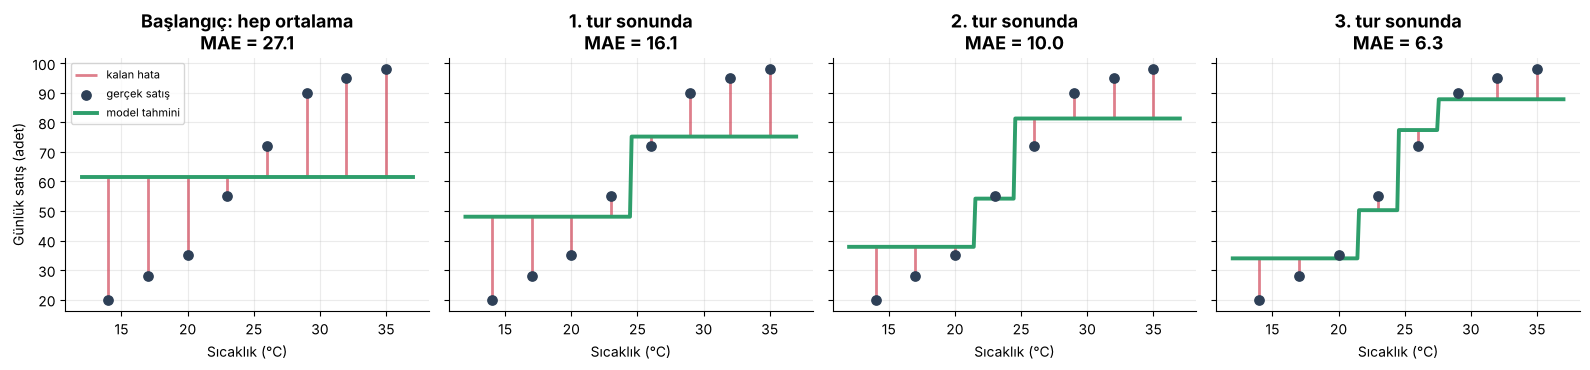

In [6]:
sx = np.linspace(12, 37, 200).reshape(-1, 1)
# yoğun ızgarada çizebilmek için aynı turları yeniden kuruyoruz (aynı sonuç, daha pürüzsüz çizim)
F_g = np.full(len(sx), y_d.mean())
F_d = np.full(len(y_d), y_d.mean())
paneller = [("Başlangıç: hep ortalama", F_g.copy(), F_d.copy())]
for tur in range(3):
    ag = DecisionTreeRegressor(max_depth=1, random_state=RANDOM_STATE).fit(X_d, y_d - F_d)
    F_g = F_g + ETA * ag.predict(sx)
    F_d = F_d + ETA * ag.predict(X_d)
    paneller.append((f"{tur + 1}. tur sonunda", F_g.copy(), F_d.copy()))

fig, eksenler = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, (baslik, fg, fd) in zip(eksenler, paneller):
    ax.vlines(X_d[:, 0], fd, y_d, color=RENK["pembe"], lw=2, alpha=0.7, label="kalan hata")
    ax.scatter(X_d[:, 0], y_d, color=RENK["koyu"], s=45, zorder=3, label="gerçek satış")
    ax.plot(sx, fg, color=RENK["yesil"], lw=2.8, label="model tahmini")
    ax.set_title(f"{baslik}\nMAE = {np.abs(y_d - fd).mean():.1f}")
    ax.set_xlabel("Sıcaklık (°C)")
eksenler[0].set_ylabel("Günlük satış (adet)")
eksenler[0].legend(fontsize=8, loc="upper left")
fig.tight_layout()
kaydet(fig, "kavram_02_dondurma_uc_tur")
plt.show()

<a id="k5"></a>

<p align="center">
  <img src="assets/kavram_05.svg" width="100%" alt="Bölüm 5 — Hata Avcısı">
</p>

Şimdi aynı fikri **gürültülü eğri** verisinde (bölüm 2'deki 70 nokta) izleyelim. Küçük ağaçlar (2 soru) ve $\eta = 0{,}3$ ile **40 tur**. Soldaki paneldeki **pembe çizgiler** modelin kalan hatasıdır; ağaçlar eklendikçe bu çizgiler kısalır. Sağdaki panel **eğitim** ve **test** hatasını tur tur gösterir.

💾 Animasyon → outputs/figures/kavram_03_hata_avcisi.gif (206 KB)


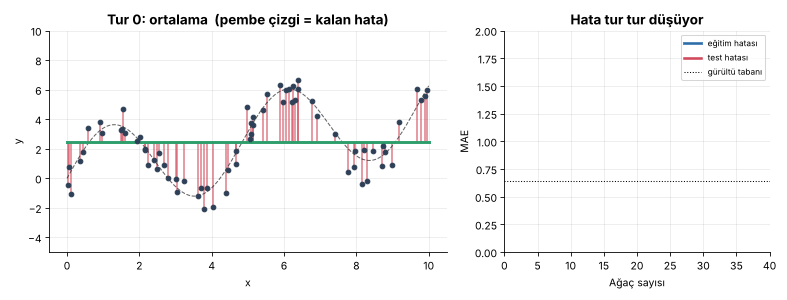

In [7]:
gb_anim = GradientBoostingRegressor(n_estimators=40, learning_rate=0.3, max_depth=2, random_state=RANDOM_STATE).fit(X_e, y_e)

# aşama 0 = ortalama; aşama k = k ağaçlı model (staged_predict her turdaki tahmini verir)
asama_izgara = [np.full(len(xs), y_e.mean())] + list(gb_anim.staged_predict(xs))
asama_egitim = [np.full(len(y_e), y_e.mean())] + list(gb_anim.staged_predict(X_e))
asama_test = [np.full(len(y_t), y_e.mean())] + list(gb_anim.staged_predict(X_t))
mae_egitim = [mean_absolute_error(y_e, p) for p in asama_egitim]
mae_test = [mean_absolute_error(y_t, p) for p in asama_test]

KARELER = [0, 1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 18, 22, 26, 31, 36, 40, 40, 40]       # sonda biraz bekle


def avci_karesi(fig, i):
    k = KARELER[i]
    fig.clf()
    ax1, ax2 = fig.subplots(1, 2, gridspec_kw={"width_ratios": [1.5, 1]})
    ax1.vlines(x_e, asama_egitim[k], y_e, color=RENK["pembe"], lw=1.6, alpha=0.65)
    ax1.scatter(x_e, y_e, s=20, color=RENK["koyu"], zorder=3)
    ax1.plot(xs, gercek(xs), color="black", lw=1, ls="--", alpha=0.6)
    ax1.plot(xs, asama_izgara[k], color=RENK["yesil"], lw=2.8)
    ax1.set(title=f"Tur {k}: {'ortalama' if k == 0 else f'{k} küçük ağaç'}  (pembe çizgi = kalan hata)", xlabel="x", ylabel="y", ylim=(-5, 10))
    ax2.plot(range(k + 1), mae_egitim[: k + 1], color=RENK["mavi"], lw=2.5, label="eğitim hatası")
    ax2.plot(range(k + 1), mae_test[: k + 1], color=RENK["pembe"], lw=2.5, label="test hatası")
    ax2.axhline(GURULTU_TABANI, color="black", lw=1, ls=":", label="gürültü tabanı")
    ax2.set(xlim=(0, 40), ylim=(0, 2), xlabel="Ağaç sayısı", ylabel="MAE", title="Hata tur tur düşüyor")
    ax2.legend(loc="upper right", fontsize=8)
    fig.tight_layout()


AVCI_GIF = FIG_DIR / "kavram_03_hata_avcisi.gif"
gif_kaydet(avci_karesi, len(KARELER), AVCI_GIF, figsize=(10.5, 4), fps=3, dpi=75)
Image(filename=AVCI_GIF, width=800)

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

**İlk birkaç ağaç hatayı hızla düşürür** (büyük hatalar kolay yakalanır), sonraki ağaçlar yalnızca ince ayar yapar. Eğitim hatası **sürekli** düşerken test hatası bir yerden sonra **düzleşir veya yükselir**: model gürültüyü de ezberlemeye başlar. İşte bu yüzden "kaç ağaç?" sorusu önemlidir (bölüm 10).

</td></tr></table>

<a id="k6"></a>

<p align="center">
  <img src="assets/kavram_06.svg" width="100%" alt="Bölüm 6 — Neden Gradient?">
</p>

"Gradient" kelimesi **eğim, yokuş** demektir. Peki "artığı öğrenmek" ile "yokuş aşağı inmek" arasında ne bağ var?

<p align="center">
  <img src="assets/diyagram_gradyan_inis.svg" width="100%" alt="Yokuş aşağı küçük adımlar">
</p>

Bir satır için **hata (kayıp)** şöyle ölçülür:

$$L(F) = \tfrac12\,(y - F)^2$$

Burada $y$ gerçek değer, $F$ bizim tahminimizdir. Bu bir **çanak** biçimindedir: tahmin gerçeğe ne kadar uzaksa kayıp o kadar yüksek. Çanağın eğimi (gradyanı) $-(y-F)$'dir; yani **eğimin ters yönü tam olarak artıktır**:

$$-\frac{\partial L}{\partial F} = y - F = \text{artık}$$

Kısacası: **artığı tahmin eden ağacı eklemek = hatanın azaldığı yöne bir adım atmak.** Aşağıda bunu sayıyla doğruluyoruz:

In [8]:
y_gercek, F_simdi = 70.0, 50.0                      # tek satır: gerçek 70, tahminimiz 50
kayip = lambda F: 0.5 * (y_gercek - F) ** 2

h = 1e-6
sayisal_egim = (kayip(F_simdi + h) - kayip(F_simdi - h)) / (2 * h)       # çanağın o noktadaki eğimi (sayısal)
print(f"Çanağın eğimi (gradyan)      : {sayisal_egim:+.2f}")
print(f"Artık (gerçek − tahmin)      : {y_gercek - F_simdi:+.2f}")
print(f"Eğimin tersi = artık mı?     : {np.isclose(-sayisal_egim, y_gercek - F_simdi)}")

Çanağın eğimi (gradyan)      : -20.00
Artık (gerçek − tahmin)      : +20.00
Eğimin tersi = artık mı?     : True


💾 Kaydedildi → outputs/figures/kavram_04_kayip_canagi.png


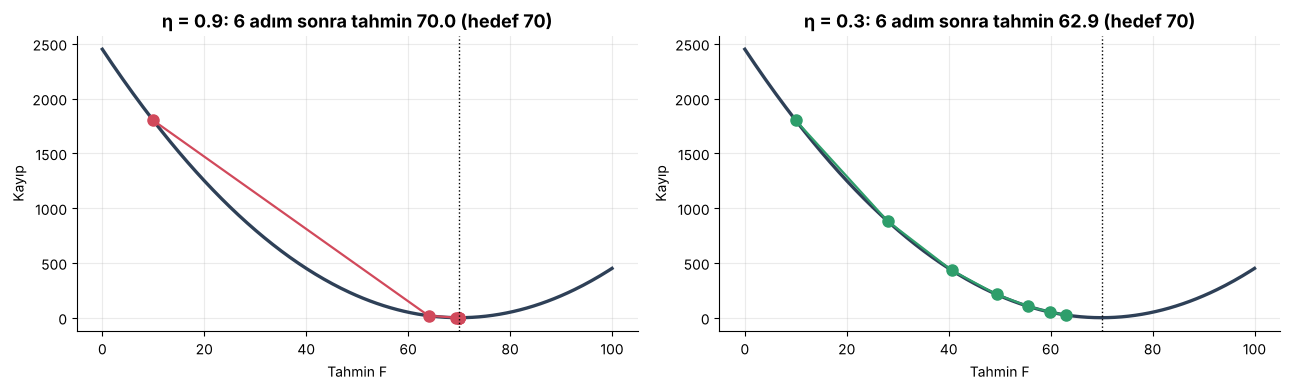

In [9]:
# Çanakta 6 adım: her adımda artığın bir kısmı (η) kadar tahmini güncelle
fig, eksenler = plt.subplots(1, 2, figsize=(13, 4))
Fg = np.linspace(0, 100, 300)
for ax, (eta, renk) in zip(eksenler, [(0.9, RENK["pembe"]), (0.3, RENK["yesil"])]):
    ax.plot(Fg, kayip(Fg), color=RENK["koyu"], lw=2.4)
    F_k = 10.0
    yol_x = [F_k]
    for _ in range(6):
        F_k = F_k + eta * (y_gercek - F_k)          # ağaç artığı tam öğrenmiş sayalım
        yol_x.append(F_k)
    ax.plot(yol_x, kayip(np.array(yol_x)), "o-", color=renk, lw=1.6, ms=8)
    ax.axvline(y_gercek, color="black", ls=":", lw=1)
    ax.set(title=f"η = {eta}: 6 adım sonra tahmin {yol_x[-1]:.1f} (hedef {y_gercek:.0f})", xlabel="Tahmin F", ylabel="Kayıp")
fig.tight_layout()
kaydet(fig, "kavram_04_kayip_canagi")
plt.show()

<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="Not">

**Neden bu bağlantı önemli?** Çünkü kayıp işlevini değiştirirsek (örneğin aykırı değerlere dayanıklı bir ölçüt seçersek) artık yerine o kaybın **eğimini** öğretiriz. Böylece aynı algoritma regresyon, sınıflandırma, dayanıklı regresyon ve hatta **kuantil** tahmini için çalışır. Bu genelleme Friedman'ın (2001) katkısıdır: AdaBoost gibi önceki boosting yöntemlerini ve özel bir kayıp ölçütü kullanan diğerlerini tek bir "yokuş aşağı" çerçevesinde birleştirir (Freund & Schapire, 1997, Friedman, 2001'den aktarma; Friedman vd., 2000, Friedman, 2001'den aktarma).

</td></tr></table>

<a id="k7"></a>

<p align="center">
  <img src="assets/kavram_07.svg" width="100%" alt="Bölüm 7 — Öğrenme Hızı">
</p>

$\eta$ (öğrenme hızı) her ağacın düzeltmesinden **ne kadarını** alacağımızı belirler. Aşağıdaki yarışta üç model aynı veride, aynı ağaç türüyle ama **farklı adım boyuyla** büyüyor:

- 🐇 **$\eta = 1$**: ağacın düzeltmesini tam uygula (çok acele)
- 🚶 **$\eta = 0{,}3$**: orta
- 🐢 **$\eta = 0{,}05$**: çok küçük adımlar

(Grafiklerde emoji yerine yazı kullanıyoruz; Matplotlib'in varsayılan yazı tipi emoji çizemez.)

💾 Animasyon → outputs/figures/kavram_05_ogrenme_hizi_yarisi.gif (249 KB)


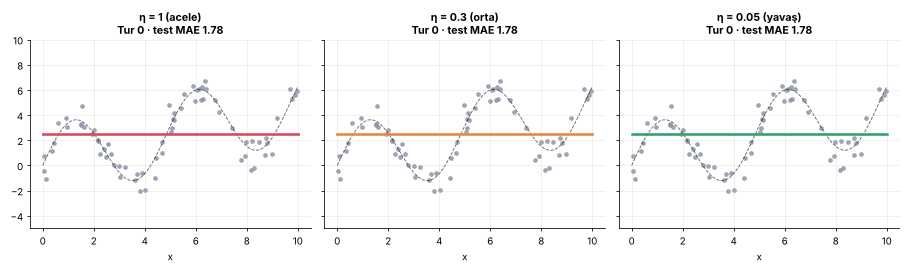

In [10]:
HIZLAR = [(1.0, "η = 1 (acele)", RENK["pembe"]), (0.3, "η = 0.3 (orta)", RENK["turuncu"]), (0.05, "η = 0.05 (yavaş)", RENK["yesil"])]
yaris = {}
for eta, ad, renk in HIZLAR:
    m = GradientBoostingRegressor(n_estimators=100, learning_rate=eta, max_depth=2, random_state=RANDOM_STATE).fit(X_e, y_e)
    yaris[eta] = {
        "izgara": [np.full(len(xs), y_e.mean())] + list(m.staged_predict(xs)),
        "test": [mean_absolute_error(y_t, np.full(len(y_t), y_e.mean()))] + [mean_absolute_error(y_t, p) for p in m.staged_predict(X_t)],
    }

KARELER_H = [0, 1, 2, 3, 4, 5, 6, 8, 10, 13, 16, 20, 25, 30, 40, 50, 65, 80, 100, 100, 100]


def yaris_karesi(fig, i):
    k = KARELER_H[i]
    fig.clf()
    eksenler = fig.subplots(1, 3, sharey=True)
    for ax, (eta, ad, renk) in zip(eksenler, HIZLAR):
        ax.scatter(x_e, y_e, s=14, color=RENK["gri"], alpha=0.8)
        ax.plot(xs, gercek(xs), color="black", lw=0.9, ls="--", alpha=0.6)
        ax.plot(xs, yaris[eta]["izgara"][k], color=renk, lw=2.6)
        ax.set_title(f"{ad}\nTur {k} · test MAE {yaris[eta]['test'][k]:.2f}", fontsize=11)
        ax.set_ylim(-5, 10)
        ax.set_xlabel("x")
    fig.tight_layout()


HIZ_GIF = FIG_DIR / "kavram_05_ogrenme_hizi_yarisi.gif"
gif_kaydet(yaris_karesi, len(KARELER_H), HIZ_GIF, figsize=(13, 3.9), fps=3, dpi=70)
Image(filename=HIZ_GIF, width=900)

### 📊 7.1 · Test Hatası Tur Tur: Kimin Eğrisi Daha Güvenli?

💾 Kaydedildi → outputs/figures/kavram_06_hiz_ve_agac_sayisi.png


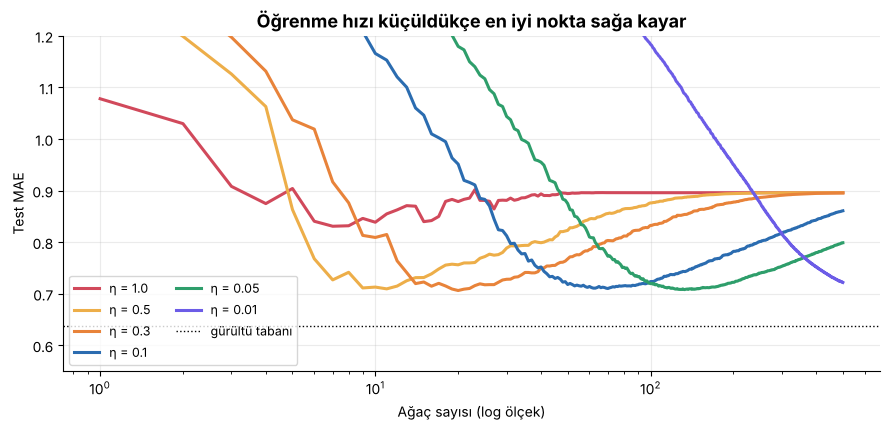

,en iyi tur,en iyi test MAE,500. turda test MAE,güvenli bölge (en iyiye %5 yakın tur sayısı)
öğrenme hızı η,,,,
1.00,7,0.831,0.896,13
0.50,11,0.709,0.896,10
0.30,20,0.706,0.895,26
0.10,70,0.710,0.861,97
0.05,133,0.708,0.799,181
0.01,500,0.722,0.722,114


In [11]:
sonuc_hiz = []
fig, ax = plt.subplots(figsize=(9, 4.4))
for eta, renk in [(1.0, RENK["pembe"]), (0.5, RENK["altin"]), (0.3, RENK["turuncu"]), (0.1, RENK["mavi"]), (0.05, RENK["yesil"]), (0.01, RENK["mor"])]:
    m = GradientBoostingRegressor(n_estimators=500, learning_rate=eta, max_depth=2, random_state=RANDOM_STATE).fit(X_e, y_e)
    egri = np.array([mean_absolute_error(y_t, p) for p in m.staged_predict(X_t)])
    ax.plot(np.arange(1, 501), egri, color=renk, lw=2.2, label=f"η = {eta}")
    sonuc_hiz.append({"öğrenme hızı η": eta, "en iyi tur": int(egri.argmin()) + 1, "en iyi test MAE": egri.min(),
                      "500. turda test MAE": egri[-1], "güvenli bölge (en iyiye %5 yakın tur sayısı)": int((egri <= egri.min() * 1.05).sum())})
ax.axhline(GURULTU_TABANI, color="black", ls=":", lw=1, label="gürültü tabanı")
ax.set(xscale="log", xlabel="Ağaç sayısı (log ölçek)", ylabel="Test MAE", title="Öğrenme hızı küçüldükçe en iyi nokta sağa kayar", ylim=(0.55, 1.2))
ax.legend(ncol=2, fontsize=9)
fig.tight_layout()
kaydet(fig, "kavram_06_hiz_ve_agac_sayisi")
plt.show()
pd.DataFrame(sonuc_hiz).round(3).set_index("öğrenme hızı η")

<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="Sonuç">

**Büyük adım hızlı öğrenir ama hemen aşırı öğrenir:** η = 1'de en iyi tur 7. turdur ve ulaşılan en iyi hata (≈0,83) diğerlerinden belirgin biçimde kötüdür. Orta ve küçük adımlar (η ≤ 0,5) benzer bir en iyi hataya (≈0,71) varır; asıl fark **vadinin genişliğidir**: tablonun son sütununa bakın. η küçüldükçe "en iyiye %5 yakın" tur sayısı büyür (η = 0,5'te 10, η = 0,3'te 26, η = 0,1'de 97, η = 0,05'te 181 tur). Yani küçük hızda **tam doğru tur sayısını tutturmak şart değildir**, büyük hızda ise birkaç tur fazlası bile hatayı bozar. (η = 0,01 hâlâ 500 turda tepeye varamadı; daha çok ağaç ister.) Pratik kural: **küçük bir öğrenme hızı seç, ağaç sayısını bol tut, doğrulama hatasıyla dur.** Friedman (2001) de küçük adımların genellemeyi iyileştirdiğini göstermiştir.

</td></tr></table>

<a id="k8"></a>

<p align="center">
  <img src="assets/kavram_08.svg" width="100%" alt="Bölüm 8 — AdaBoost'tan Farkı">
</p>

Geçen derste **AdaBoost**'u (Gün 46–47) gördük. İki yöntem de "sırayla, öncekinin hatasından öğrenen küçük modeller" fikrine dayanır; ama hatayı **farklı anlatırlar**:

<p align="center">
  <img src="assets/diyagram_adaboost_gb.svg" width="100%" alt="AdaBoost ile Gradient Boosting">
</p>

| | 🎡 AdaBoost | 🏔️ Gradient Boosting |
|:--|:--|:--|
| **Hatayı nasıl iletir?** | Zor satırların **ağırlığını** büyütür | Hedefi **artığa** çevirir |
| **Yeni model neyi öğrenir?** | Ağırlıklı satırlar üzerinde asıl hedefi | Artığı (kalan hatayı) |
| **Modellerin sözü** | Her modelin oy hakkı ($\alpha$) farklı | Hepsi eşit, ama $\eta$ ile küçültülür |
| **Zayıf öğrenici** | Genelde kütük (derinlik 1) | Biraz daha derin küçük ağaç (3–8 yaprak) |
| **Esneklik** | Belirli bir kayıp (üstel) | **Herhangi bir türevlenebilir kayıp** (kare, mutlak, Huber, kuantil, log) |

Aynı veride ikisini yan yana koyalım (ikisi de **en fazla** 100 ağaç, derinlik 3):

💾 Kaydedildi → outputs/figures/kavram_07_adaboost_gradient_boosting.png


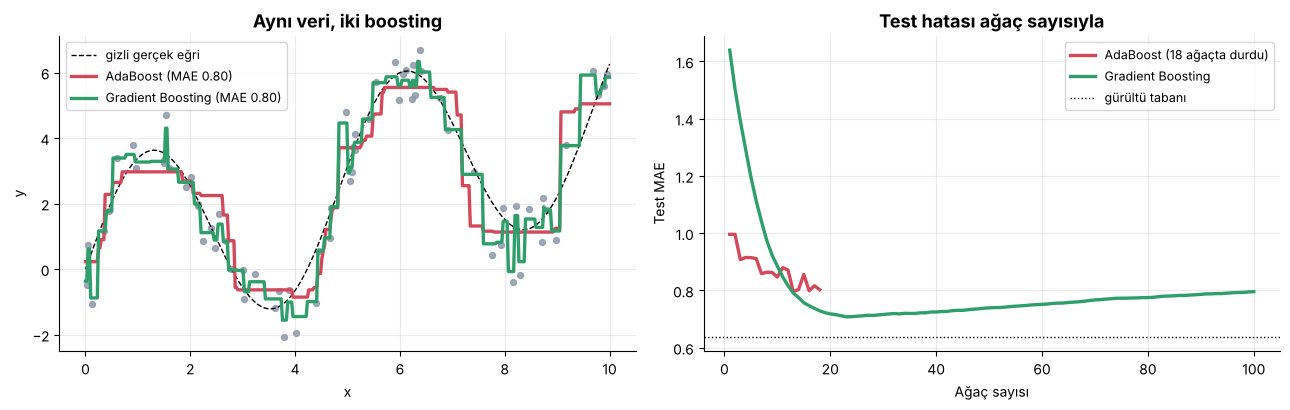

Test MAE → AdaBoost: 0.803 (18 ağaç kullandı) | Gradient Boosting: 0.796 (100 ağaç)


In [12]:
ab = AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=3), n_estimators=100, random_state=RANDOM_STATE).fit(X_e, y_e)
gb = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=RANDOM_STATE).fit(X_e, y_e)

mae_ab = [mean_absolute_error(y_t, p) for p in ab.staged_predict(X_t)]
mae_gb = [mean_absolute_error(y_t, p) for p in gb.staged_predict(X_t)]

fig, eksenler = plt.subplots(1, 2, figsize=(13, 4.2))
eksenler[0].scatter(x_e, y_e, s=18, color=RENK["gri"], alpha=0.8)
eksenler[0].plot(xs, gercek(xs), color="black", lw=1, ls="--", label="gizli gerçek eğri")
eksenler[0].plot(xs, ab.predict(xs), color=RENK["pembe"], lw=2.4, label=f"AdaBoost (MAE {mae_ab[-1]:.2f})")
eksenler[0].plot(xs, gb.predict(xs), color=RENK["yesil"], lw=2.4, label=f"Gradient Boosting (MAE {mae_gb[-1]:.2f})")
eksenler[0].set(title="Aynı veri, iki boosting", xlabel="x", ylabel="y"); eksenler[0].legend(fontsize=9)
eksenler[1].plot(range(1, len(mae_ab) + 1), mae_ab, color=RENK["pembe"], lw=2.4, label=f"AdaBoost ({len(mae_ab)} ağaçta durdu)")
eksenler[1].plot(range(1, 101), mae_gb, color=RENK["yesil"], lw=2.4, label="Gradient Boosting")
eksenler[1].axhline(GURULTU_TABANI, color="black", ls=":", lw=1, label="gürültü tabanı")
eksenler[1].set(title="Test hatası ağaç sayısıyla", xlabel="Ağaç sayısı", ylabel="Test MAE"); eksenler[1].legend(fontsize=9)
fig.tight_layout()
kaydet(fig, "kavram_07_adaboost_gradient_boosting")
plt.show()
print(f"Test MAE → AdaBoost: {mae_ab[-1]:.3f} ({len(ab.estimators_)} ağaç kullandı) | Gradient Boosting: {mae_gb[-1]:.3f} ({gb.n_estimators_} ağaç)")

<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="Not">

**AdaBoost 100 ağacın hepsini kullanmadı:** `AdaBoostRegressor` bir turdaki ağırlıklı hata 0,5'i aştığında (yeni ağaç "yazı-tura"dan iyi değilse) kendiliğinden durur. Gradient Boosting'de böyle bir kesme yoktur; ağaç sayısını ve durma kararını **biz** (veya erken durdurma) veririz. Ayrıca bu tek küçük veride fark **kural değil, örnektir**. Gerçek tablolarda (örneğin bu dersin ikinci yarısındaki beton projesinde) iki yöntem 25 algoritmayla **aynı pistte** karşılaştırılır. AdaBoost'un asıl avantajı sadeliği; Gradient Boosting'in avantajı **kayıp işlevini seçebilmek** ve ayar düğmelerinin zenginliğidir.

</td></tr></table>

<a id="k9"></a>

<p align="center">
  <img src="assets/kavram_09.svg" width="100%" alt="Bölüm 9 — Sıfırdan Kodlama">
</p>

Beş adımı yaklaşık **15 satırda** kodlayalım. Hiçbir sihir yok: bir ortalama, bir döngü ve küçük ağaçlar.

In [13]:
class BenimGradientBoosting:
    """Kare hatalı regresyon için Gradient Boosting'in en yalın hali."""

    def __init__(self, n_agac=100, hiz=0.1, derinlik=3):
        self.n_agac, self.hiz, self.derinlik = n_agac, hiz, derinlik

    def fit(self, X, y):
        y = np.asarray(y, dtype=float)
        self.baslangic = y.mean()                              # adım 1: ortalama
        tahmin = np.full(len(y), self.baslangic)
        self.agaclar = []
        for _ in range(self.n_agac):
            artik = y - tahmin                                 # adım 2: kalan hata
            agac = DecisionTreeRegressor(max_depth=self.derinlik).fit(X, artik)   # adım 3: artığı öğren
            tahmin = tahmin + self.hiz * agac.predict(X)       # adım 4: küçük adımla ekle
            self.agaclar.append(agac)                          # adım 5: döngü devam
        return self

    def predict(self, X):
        return self.baslangic + self.hiz * sum(a.predict(X) for a in self.agaclar)


benim = BenimGradientBoosting(n_agac=100, hiz=0.1, derinlik=3).fit(X_e, y_e)
sk = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, criterion="squared_error", random_state=RANDOM_STATE).fit(X_e, y_e)

fark = np.abs(benim.predict(X_t) - sk.predict(X_t)).max()
print(f"Test noktalarında en büyük tahmin farkı (bizimki vs scikit-learn): {fark:.2e}")
print(f"Test MAE → bizimki: {mean_absolute_error(y_t, benim.predict(X_t)):.4f} | scikit-learn: {mean_absolute_error(y_t, sk.predict(X_t)):.4f}")

Test noktalarında en büyük tahmin farkı (bizimki vs scikit-learn): 6.22e-15
Test MAE → bizimki: 0.7957 | scikit-learn: 0.7957


### ✅ 9.1 · Çok Özellikli Gerçek Bir Tabloda da Aynı mı?

Tek özellikli eğri kolaydı. `scikit-learn`'ün içinde gelen **diyabet** tablosunda (442 hasta, 10 özellik, hedef: bir yıl sonraki hastalık ilerlemesi) deneyelim:

In [14]:
Xd, yd = load_diabetes(return_X_y=True)
Xd_e, Xd_t, yd_e, yd_t = train_test_split(Xd, yd, test_size=0.25, random_state=RANDOM_STATE)

benim_d = BenimGradientBoosting(n_agac=100, hiz=0.1, derinlik=3).fit(Xd_e, yd_e)
sk_d = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, criterion="squared_error", random_state=RANDOM_STATE).fit(Xd_e, yd_e)

print(f"Hep ortalama MAE  : {mean_absolute_error(yd_t, np.full(len(yd_t), yd_e.mean())):.2f}")
print(f"Bizim kodumuz MAE : {mean_absolute_error(yd_t, benim_d.predict(Xd_t)):.2f}")
print(f"scikit-learn MAE  : {mean_absolute_error(yd_t, sk_d.predict(Xd_t)):.2f}")
print(f"En büyük tahmin farkı: {np.abs(benim_d.predict(Xd_t) - sk_d.predict(Xd_t)).max():.2e}")

Hep ortalama MAE  : 65.53
Bizim kodumuz MAE : 44.25
scikit-learn MAE  : 44.26
En büyük tahmin farkı: 4.08e+00


<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="Sonuç">

**Tek özellikli eğride tahminler birebir aynı** (fark ≈ 10⁻¹⁵, yani yalnızca kayan nokta yuvarlaması). **10 özellikli diyabet tablosunda** ortalama hatalar pratikte aynı (≈ 44) ama bazı tek tahminler birkaç birim ayrışıyor. Nedeni bir hata değil: birden çok özellik varken iki bölme **neredeyse eşit iyi** olabilir ve ağaç hangisini seçeceğine rastgele bir sıralamayla karar verir; seçimler ayrışınca sonraki turlar da biraz farklı yolu izler. (Bizim sınıftaki ağaçlara farklı `random_state` verdiğimizde en büyük fark değişir; bu da açıklamayı destekler.) Demek ki `GradientBoostingRegressor`'ın içinde gizli bir sır yok: **ortalama + küçük ağaçların artık düzeltmeleri**. scikit-learn ek olarak hız, farklı kayıp işlevleri, rastgele alt örnekleme ve erken durdurma gibi kolaylıklar ekler.

</td></tr></table>

<a id="k10"></a>

<p align="center">
  <img src="assets/kavram_10.svg" width="100%" alt="Bölüm 10 — Düğmeler">
</p>

Gradient Boosting'in başlıca altı düğmesi var:

<p align="center">
  <img src="assets/diyagram_gb_dugmeleri.svg" width="100%" alt="Gradient Boosting düğmeleri">
</p>

Her birini küçük bir deneyle çevirelim.

### 🎚️ 10.1 · Ağaç Derinliği ve Ağaç Sayısı

Derinlik arttıkça her ağaç **daha çok soru** sorar. Eğitim ve test hatasını üç derinlik için çizelim (η = 0.1):

💾 Kaydedildi → outputs/figures/kavram_08_derinlik.png


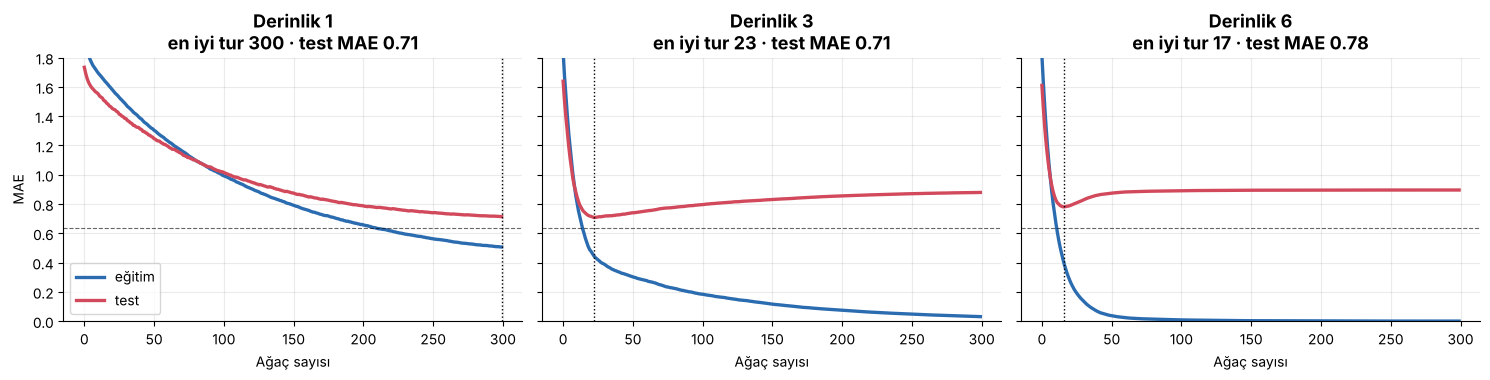

,en iyi tur,en iyi test MAE,300. turda eğitim MAE
derinlik,,,
1,300,0.714,0.506
3,23,0.708,0.031
6,17,0.781,0.000


In [15]:
fig, eksenler = plt.subplots(1, 3, figsize=(15, 3.9), sharey=True)
derinlik_sonuc = []
for ax, d in zip(eksenler, [1, 3, 6]):
    m = GradientBoostingRegressor(n_estimators=300, learning_rate=0.1, max_depth=d, random_state=RANDOM_STATE).fit(X_e, y_e)
    e_egri = [mean_absolute_error(y_e, p) for p in m.staged_predict(X_e)]
    t_egri = [mean_absolute_error(y_t, p) for p in m.staged_predict(X_t)]
    ax.plot(e_egri, color=RENK["mavi"], lw=2.4, label="eğitim")
    ax.plot(t_egri, color=RENK["pembe"], lw=2.4, label="test")
    ax.axvline(int(np.argmin(t_egri)), color="black", ls=":", lw=1)
    ax.axhline(GURULTU_TABANI, color="black", ls="--", lw=0.8, alpha=0.6)
    ax.set(title=f"Derinlik {d}\nen iyi tur {int(np.argmin(t_egri)) + 1} · test MAE {min(t_egri):.2f}", xlabel="Ağaç sayısı", ylim=(0, 1.8))
    derinlik_sonuc.append({"derinlik": d, "en iyi tur": int(np.argmin(t_egri)) + 1, "en iyi test MAE": min(t_egri), "300. turda eğitim MAE": e_egri[-1]})
eksenler[0].set_ylabel("MAE"); eksenler[0].legend()
fig.tight_layout()
kaydet(fig, "kavram_08_derinlik")
plt.show()
pd.DataFrame(derinlik_sonuc).round(3).set_index("derinlik")

**Okuma:** Derinlik arttıkça eğitim hatası **daha hızlı sıfıra iner**: derinlik 3'te 300. turda eğitim hatası ≈ 0,03, derinlik 6'da 0,00 (model eğitim noktalarını ezberlemiş). Derinlik 6'nın en iyi test hatası (≈ 0,78) derinlik 3'ünkinden (≈ 0,71) **daha kötü** ve en iyi tur daha erken (17. tur). Kütüklerde (derinlik 1) ise eğri 300. turda bile hâlâ iniyor: bu basit eğri için kütük de iş görür ama daha çok tur ister. Özellikler arası etkileşimlerin olduğu tablolarda biraz derinlik gerekir; ideal değeri hiperparametre aramasıyla buluruz.

### 🎲 10.2 · Alt Örnekleme (Rastgelelik)

Her turda satırların **yalnızca yarısı** (`subsample=0.5`) kullanılırsa ağaçlar birbirinden biraz farklılaşır. Bu çeşitlilik genellemeyi çoğu zaman iyileştirir (stokastik gradyan artırma; Friedman, 2002). Tek bir rastgele tohumun şansından kaçınmak için **10 farklı tohumun ortalamasına** bakıyoruz:

💾 Kaydedildi → outputs/figures/kavram_09_alt_ornekleme.png


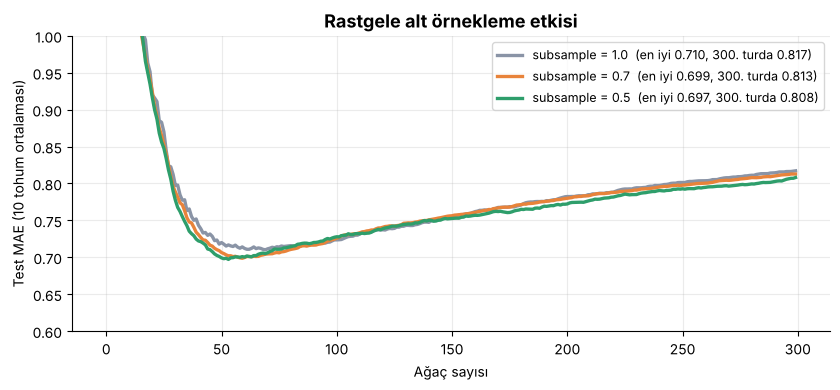

In [16]:
sonuc_alt = {}
for alt in (1.0, 0.7, 0.5):
    egriler = []
    for tohum in range(10):
        m = GradientBoostingRegressor(n_estimators=300, learning_rate=0.1, max_depth=2, subsample=alt, random_state=tohum).fit(X_e, y_e)
        egriler.append([mean_absolute_error(y_t, p) for p in m.staged_predict(X_t)])
    sonuc_alt[alt] = np.mean(egriler, axis=0)

fig, ax = plt.subplots(figsize=(8.5, 4))
for (alt, egri), renk in zip(sonuc_alt.items(), [RENK["gri"], RENK["turuncu"], RENK["yesil"]]):
    ax.plot(egri, lw=2.4, color=renk, label=f"subsample = {alt}  (en iyi {egri.min():.3f}, 300. turda {egri[-1]:.3f})")
ax.set(xlabel="Ağaç sayısı", ylabel="Test MAE (10 tohum ortalaması)", title="Rastgele alt örnekleme etkisi", ylim=(0.6, 1.0))
ax.legend(fontsize=9)
fig.tight_layout()
kaydet(fig, "kavram_09_alt_ornekleme")
plt.show()

**Okuma:** Rastgele alt örnekleme **hafif** bir iyileşme getiriyor: en iyi test MAE'si `subsample=1.0` için ≈ 0,710, `0.7` için ≈ 0,699, `0.5` için ≈ 0,697 (300. turda 0,817 → 0,808). Fark yaklaşık **0,01 MPa-birimi**, yani bu küçük veride abartılacak bir kazanç değil; asıl faydası, eğrinin **tepe noktasında** ve çok ağaçlı bölgede biraz daha az aşırı öğrenmektir. (Büyük tablolarda etkisi genelde daha belirgindir; bölüm "Proje"de gerçek veriyle ölçeceğiz.)

### 🛑 10.3 · Erken Durdurma

Kaç ağaç yeterli olduğunu **elle aramak** yerine, modele "doğrulama hatası 10 tur boyunca iyileşmezse dur" diyebiliriz. Eğitim verisinin %20'si içeriden ayrılıp doğrulama için kullanılır:

In [17]:
erken = GradientBoostingRegressor(n_estimators=2000, learning_rate=0.05, max_depth=2, validation_fraction=0.2,
                                  n_iter_no_change=15, tol=1e-4, random_state=RANDOM_STATE).fit(X_e, y_e)
print(f"En fazla 2000 ağaca izin verdik; model {erken.n_estimators_} ağaçta kendiliğinden durdu.")
print(f"Test MAE: {mean_absolute_error(y_t, erken.predict(X_t)):.3f}")

En fazla 2000 ağaca izin verdik; model 143 ağaçta kendiliğinden durdu.
Test MAE: 0.753


### ⚖️ 10.4 · Kayıp İşlevi: Aykırı Değerlere Karşı

Gerçek veride bazen **hatalı ölçümler** olur. Eğitim verisinin 6 noktasına yapay olarak **+15 birim hata** ekleyelim ve üç kayıp işleviyle (kare, Huber, mutlak) eğitelim. Test seti **temiz**.

,temiz,kirli,kirlenmenin bedeli
Huber (karma),0.752,1.272,0.520
Kare hata (varsayılan),0.754,2.211,1.457
Mutlak hata,0.710,0.723,0.013


💾 Kaydedildi → outputs/figures/kavram_10_kayip_islevleri.png


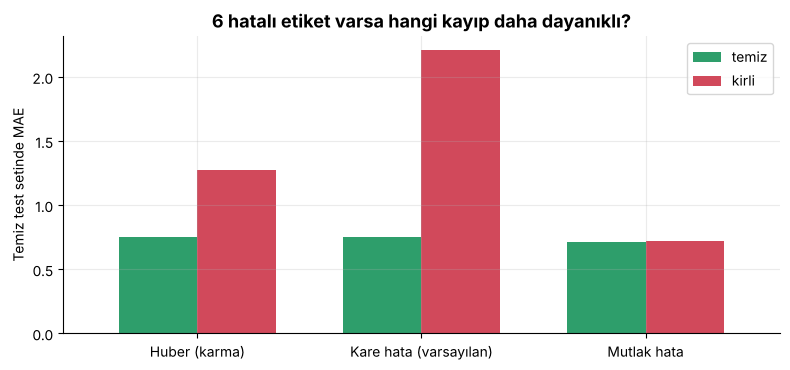

In [18]:
rng_k = np.random.default_rng(3)
y_kirli = y_e.copy()
kirli_idx = rng_k.choice(len(y_e), 6, replace=False)
y_kirli[kirli_idx] += 15                                        # 6 hatalı ölçüm

kayip_sonuc = {}
for kayip_ad, ad_tr in [("squared_error", "Kare hata (varsayılan)"), ("huber", "Huber (karma)"), ("absolute_error", "Mutlak hata")]:
    for etiket, yy in [("temiz", y_e), ("kirli", y_kirli)]:
        m = GradientBoostingRegressor(loss=kayip_ad, n_estimators=150, learning_rate=0.1, max_depth=2, random_state=RANDOM_STATE).fit(X_e, yy)
        kayip_sonuc[(ad_tr, etiket)] = mean_absolute_error(y_t, m.predict(X_t))
kt = pd.Series(kayip_sonuc).unstack().round(3)
kt["kirlenmenin bedeli"] = (kt["kirli"] - kt["temiz"]).round(3)
display(kt[["temiz", "kirli", "kirlenmenin bedeli"]])

fig, ax = plt.subplots(figsize=(8, 3.8))
kt[["temiz", "kirli"]].plot.bar(ax=ax, color=[RENK["yesil"], RENK["pembe"]], rot=0, width=0.7)
ax.set(ylabel="Temiz test setinde MAE", title="6 hatalı etiket varsa hangi kayıp daha dayanıklı?", xlabel="")
fig.tight_layout()
kaydet(fig, "kavram_10_kayip_islevleri")
plt.show()

<table><tr><td>

<img src="assets/etiket_ipucu.svg" height="34" alt="İpucu">

**Neden Huber / mutlak hata dayanıklı?** Kare hatada büyük artık **karesiyle** cezalandırıldığı için ağaçlar aykırı noktaları kovalamaya başlar. Mutlak hatada ağaçlar artığın **büyüklüğüne değil işaretine** bakar; Huber ise küçük hatalarda kare, büyük hatalarda mutlak davranır (Huber, 1964). Bu esnekliğin kaynağı, bölüm 6'daki "kayıp işlevinin eğimini öğren" fikridir.

</td></tr></table>

<a id="k11"></a>

<p align="center">
  <img src="assets/kavram_11.svg" width="100%" alt="Bölüm 11 — Sınıflandırma">
</p>

Şimdiye kadar **sayı** tahmin ettik (regresyon). Gradient Boosting **kategori** de tahmin edebilir. Fikir aynı: ağaçlar, doğrudan olasılığı değil **olasılığın bir dönüşümünü (log-odds)** adım adım düzeltir; en sonda bu toplam bir olasılığa çevrilir. Detayı bu derste açmıyoruz; yalnızca **karar sınırının nasıl büyüdüğünü** izleyelim.

İki "yarım ay" biçiminde, iç içe geçmiş iki sınıfımız var. Tek bir doğru çizgi bunları ayıramaz; ama **60 küçük ağaç** kıvrımlı bir sınır çizebilir.

💾 Animasyon → outputs/figures/kavram_11_karar_siniri.gif (288 KB)


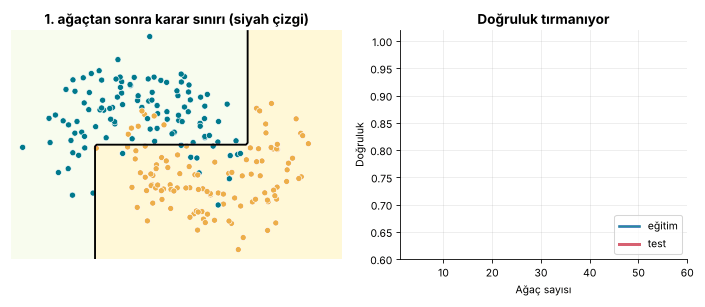

In [19]:
Xm, ym = make_moons(n_samples=320, noise=0.28, random_state=5)
Xm_e, Xm_t, ym_e, ym_t = train_test_split(Xm, ym, test_size=0.3, random_state=RANDOM_STATE, stratify=ym)

gbc = GradientBoostingClassifier(n_estimators=60, learning_rate=0.2, max_depth=2, random_state=RANDOM_STATE).fit(Xm_e, ym_e)

gx, gy = np.meshgrid(np.arange(-1.8, 2.9, 0.05), np.arange(-1.3, 1.9, 0.05))
izgara = np.c_[gx.ravel(), gy.ravel()]
sinir = [p[:, 1].reshape(gx.shape) for p in gbc.staged_predict_proba(izgara)]            # her turdaki "sınıf 1 olasılığı" haritası
dog_e = [accuracy_score(ym_e, p) for p in gbc.staged_predict(Xm_e)]
dog_t = [accuracy_score(ym_t, p) for p in gbc.staged_predict(Xm_t)]
SIN_RENK = {0: "#00798C", 1: "#EDAE49"}
KARELER_S = [0, 1, 2, 3, 4, 6, 8, 11, 15, 20, 26, 33, 41, 50, 59, 59, 59]


def sinir_karesi(fig, i):
    k = KARELER_S[i]
    fig.clf()
    ax1, ax2 = fig.subplots(1, 2, gridspec_kw={"width_ratios": [1.15, 1]})
    ax1.contourf(gx, gy, sinir[k], levels=np.linspace(0, 1, 11), cmap="RdYlBu_r", alpha=0.45)
    ax1.contour(gx, gy, sinir[k], levels=[0.5], colors="black", linewidths=1.8)
    ax1.scatter(Xm_e[:, 0], Xm_e[:, 1], c=[SIN_RENK[int(s)] for s in ym_e], edgecolor="white", linewidth=0.6, s=34)
    ax1.set(title=f"{k + 1}. ağaçtan sonra karar sınırı (siyah çizgi)", xticks=[], yticks=[])
    ax1.grid(False); ax1.spines[["left", "bottom"]].set_visible(False)
    ax2.plot(range(1, k + 2), dog_e[: k + 1], color=RENK["mavi"], lw=2.5, label="eğitim")
    ax2.plot(range(1, k + 2), dog_t[: k + 1], color=RENK["pembe"], lw=2.5, label="test")
    ax2.set(xlim=(1, 60), ylim=(0.6, 1.02), xlabel="Ağaç sayısı", ylabel="Doğruluk", title="Doğruluk tırmanıyor")
    ax2.legend(loc="lower right")
    fig.tight_layout()


SINIR_GIF = FIG_DIR / "kavram_11_karar_siniri.gif"
gif_kaydet(sinir_karesi, len(KARELER_S), SINIR_GIF, figsize=(9.4, 4.1), fps=3, dpi=75)
Image(filename=SINIR_GIF, width=760)

In [20]:
print(f"Son durum → eğitim doğruluğu: {dog_e[-1]:.3f} | test doğruluğu: {dog_t[-1]:.3f}")
print(f"En iyi test doğruluğu {max(dog_t):.3f} ile {int(np.argmax(dog_t)) + 1}. ağaçta görüldü.")

Son durum → eğitim doğruluğu: 0.987 | test doğruluğu: 0.906
En iyi test doğruluğu 0.917 ile 27. ağaçta görüldü.


<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

İlk ağaçlar **kaba bir dikdörtgen** sınır çizer; sonraki ağaçlar yalnızca **hâlâ yanlış sınıflanan bölgelere** odaklanır ve sınırı inceltip kıvırır. Eğitim doğruluğu yükselmeye devam ederken test doğruluğu bir noktada **durur**; yine "daha çok ağaç = daha iyi" değildir.

</td></tr></table>

<a id="k12"></a>

<p align="center">
  <img src="assets/kavram_12.svg" width="100%" alt="Bölüm 12 — Aile ve Özet">
</p>

Gradient Boosting bir **tek algoritma değil, bir ailenin atasıdır**. Friedman (2001) çerçevesini kurduktan sonra, mühendisler onu **daha hızlı, daha ölçeklenebilir ve daha akıllı** hâle getirdi:

<p align="center">
  <img src="assets/diyagram_aile.svg" width="100%" alt="Boosting ailesi">
</p>

| Üye | Ne getirdi? (kısaca) |
|:--|:--|
| 🎲 **Stochastic GB** (Friedman, 2002) | Her turda satırların bir alt kümesi: rastgelelikle daha iyi genelleme |
| 🚀 **XGBoost** (Chen & Guestrin, 2016) | Düzenlileştirme, ikinci türev bilgisi, eksik değer yönetimi, çok hızlı uygulama |
| ⚡ **LightGBM** (Ke vd., 2017) | Histogram + yaprak odaklı büyüme: büyük veride çok hızlı |
| 🐱 **CatBoost** (Prokhorenkova vd., 2018) | Kategorik özelliklerde sızıntıyı azaltan sıralı kodlama |
| 📊 **HistGradientBoosting** (scikit-learn) | LightGBM'den esinlenen, sklearn içinde hızlı histogram tabanlı sürüm |

Bu ailenin hepsini bir sonraki projede (**beton dayanımı tahmini**) aynı pistte, **25 algoritmayla** yarıştıracağız.

### 🧠 Akılda Kalacaklar

<table>
<tr><td width="33%" valign="top" align="center"><h3>📉</h3><b>Artığı öğren</b><br><sub><i>Residual fitting</i></sub><br><br>Her ağacın hedefi <b>kalan hata</b>dır (gerçek − tahmin)<br><br></td><td width="33%" valign="top" align="center"><h3>➕</h3><b>Toplam model</b><br><sub><i>F = F₀ + η·Σ ağaç</i></sub><br><br>Nihai tahmin: <b>ortalama + küçük düzeltmelerin toplamı</b><br><br></td><td width="33%" valign="top" align="center"><h3>🐢</h3><b>Öğrenme hızı</b><br><sub><i>η (eta)</i></sub><br><br>Küçük adım + çok ağaç = <b>güvenli</b> ve çoğu zaman daha iyi<br><br></td></tr>
<tr><td width="33%" valign="top" align="center"><h3>🏔️</h3><b>Gradient = yokuş</b><br><sub><i>Negatif gradyan</i></sub><br><br>Kare kayıpta <b>artık = −eğim</b>; ağaç eklemek yokuş aşağı bir adımdır<br><br></td><td width="33%" valign="top" align="center"><h3>⚖️</h3><b>Kayıp esnekliği</b><br><sub><i>Huber, mutlak, kuantil</i></sub><br><br>Kaybı değiştir, algoritma aynı kalsın: <b>dayanıklı regresyon, kuantil, sınıflandırma</b><br><br></td><td width="33%" valign="top" align="center"><h3>🛑</h3><b>Ne zaman dur?</b><br><sub><i>Erken durdurma</i></sub><br><br>Doğrulama hatası iyileşmiyorsa <b>dur</b>; eğitim hatası yanıltıcıdır<br><br></td></tr>
</table>

### ⚖️ Artılar ve Eksiler

| ✅ Artılar | ⚠️ Eksiler |
|:--|:--|
| Tablo verisinde **çok yüksek doğruluk** (ağaç toplulukları tablo verisinde hâlâ en güçlüler arasında; Grinsztajn vd., 2022) | **Ardışık** olduğu için Random Forest kadar kolay paralelleşmez |
| **Ölçekleme gerektirmez**, doğrusal olmayan etkileşimleri yakalar | **Hiperparametre ayarı** (hız, tur, derinlik…) gerektirir |
| Kayıp işlevi seçilebilir (kare, Huber, kuantil, …) | **Gürültüye / aykırı değere** (kare kayıpta) duyarlı olabilir |
| Özellik önemi ve kısmi bağımlılık ile yorumlanabilir | Ağaçlar **eğitim aralığının dışına çıkamaz** (ekstrapolasyon yapmaz) |
| Küçük adımlarla **genellemesi iyi** | Çok ağaç + büyük hız = **aşırı öğrenme** |

### 📝 Mini Quiz

<details><summary><b>1.</b> Gradient Boosting'de her yeni ağaç neyi öğrenir?</summary>

Gerçek değeri değil, **modelin o ana kadarki kalan hatasını (artığını)**: $\text{gerçek} - \text{tahmin}$.
</details>

<details><summary><b>2.</b> Başlangıç tahmini neden genelde hedefin ortalamasıdır?</summary>

Kare hata için **tek bir sabit sayı** seçmem gerekirse hatayı en aza indiren değer ortalamadır. Böylece ağaçlar işe "en iyi sabit tahminden" başlar.
</details>

<details><summary><b>3.</b> Öğrenme hızı η = 0.1 ise bir ağacın önerdiği düzeltmenin ne kadarı tahmine eklenir? Neden tamamını eklemeyiz?</summary>

**Onda biri.** Tamamını eklersek model her turda aşırı büyük adım atar, gürültüyü hemen ezberler ve genellemesi kötüleşir. Küçük adımlar daha fazla ağaç ister ama çoğu zaman daha iyi test hatası verir.
</details>

<details><summary><b>4.</b> "Gradient" kelimesi bu algoritmada neye karşılık gelir?</summary>

**Kayıp işlevinin eğimine.** Kare hatada negatif eğim tam olarak artıktır; yani artığı öğrenen ağacı eklemek, hatanın azaldığı yöne (yokuş aşağı) bir adım atmaktır.
</details>

<details><summary><b>5.</b> AdaBoost ile Gradient Boosting'in temel farkı nedir?</summary>

AdaBoost zor satırların **ağırlığını** büyütür ve modellere **oy hakkı** verir; Gradient Boosting hedefi **artığa** çevirir ve ağaçları **toplar**. İkincisi herhangi bir türevlenebilir kayıp işleviyle çalışabilir.
</details>

<details><summary><b>6.</b> Eğitim hatası sürekli düşüyor ama test hatası yükselmeye başladı. Ne yapmalısınız?</summary>

Model **aşırı öğreniyor**. Ağaç sayısını azaltın veya **erken durdurma** kullanın; öğrenme hızını küçültüp `subsample`'ı düşürün; ağaç derinliğini azaltın.
</details>

<details><summary><b>7.</b> Eğitim verisinde hatalı ölçümler (aykırı değerler) varsa hangi kayıp işlevini düşünürsünüz?</summary>

**Huber** veya **mutlak hata**: büyük artıklar karesiyle cezalandırılmaz, böylece ağaçlar aykırı noktaları kovalamaz.
</details>

### 🏠 Ödevler

1. **Dört tur, elle:** Dondurma tablosunda η = 0.5 ile **tur 4 ve 5**'i de çalıştırın. MAE kaçıncı turda 3'ün altına iner? Aynı işi η = 1 ile yapın; hangisi daha hızlı, hangisi daha dengeli?
2. **Tahmin hatası haritası:** Bölüm 5'teki animasyonu `max_depth=1` ile yeniden üretin. Kütüklerle (tek soru) eğri neden daha "basamaklı" kalıyor?
3. **Öğrenme hızı ızgarası:** Bölüm 7.1'de `max_depth=3` kullanın. En iyi tur ve en iyi MAE nasıl değişti?
4. **Kayıp değişimi:** Bölüm 10.4'te kirli nokta sayısını 6'dan 15'e çıkarın. Hangi kayıp işlevi en çok bozuldu?
5. **Kuantil:** `loss="quantile", alpha=0.9` ile modeli eğitin; test noktalarının yaklaşık yüzde kaçı tahminin altında kalıyor? (İpucu: `alpha=0.9` → %90 civarı beklenir.)
6. **Kendi sınıfınızı genişletin:** `BenimGradientBoosting`'e `subsample` parametresi ekleyin (her turda satırların bir kısmını rastgele seçin). Test hatası değişti mi?

### 📚 Kaynakça

Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. In *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining* (pp. 785–794). ACM. https://doi.org/10.1145/2939672.2939785

Freund, Y., & Schapire, R. E. (1997). A decision-theoretic generalization of on-line learning and an application to boosting. *Journal of Computer and System Sciences, 55*(1), 119–139. https://doi.org/10.1006/jcss.1997.1504

Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232. https://doi.org/10.1214/aos/1013203451

Friedman, J. H. (2002). Stochastic gradient boosting. *Computational Statistics & Data Analysis, 38*(4), 367–378. https://doi.org/10.1016/S0167-9473(01)00065-2

Friedman, J., Hastie, T., & Tibshirani, R. (2000). Additive logistic regression: A statistical view of boosting. *The Annals of Statistics, 28*(2), 337–407. https://doi.org/10.1214/aos/1016218223

Grinsztajn, L., Oyallon, E., & Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? In *Advances in Neural Information Processing Systems 35 (NeurIPS 2022), Datasets and Benchmarks Track*.

Huber, P. J. (1964). Robust estimation of a location parameter. *The Annals of Mathematical Statistics, 35*(1), 73–101. https://doi.org/10.1214/aoms/1177703732

Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. In *Advances in Neural Information Processing Systems 30* (pp. 3146–3154).

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A. V., & Gulin, A. (2018). CatBoost: Unbiased boosting with categorical features. In *Advances in Neural Information Processing Systems 31* (pp. 6638–6648).

> ℹ️ **Dolaylı atıf notu:** AdaBoost'un (Freund & Schapire, 1997) ve "boosting'e istatistiksel bakış"ın (Friedman vd., 2000) Gradient Boosting'e nasıl bağlandığı, **birincil kaynakları okumadan, Friedman (2001) üzerinden** aktarılmıştır; metindeki bu atıflar bu yüzden "…'den aktarma" biçimindedir.

In [21]:
for dosya in sorted(FIG_DIR.glob("kavram_*")):
    print(f"{dosya.as_posix():<62} {dosya.stat().st_size / 1024:>8.1f} KB")

outputs/figures/kavram_01_tek_model_mi_ekip_mi.png                155.3 KB
outputs/figures/kavram_02_dondurma_uc_tur.png                      88.7 KB
outputs/figures/kavram_03_hata_avcisi.gif                         206.2 KB
outputs/figures/kavram_04_kayip_canagi.png                        106.1 KB
outputs/figures/kavram_05_ogrenme_hizi_yarisi.gif                 249.3 KB
outputs/figures/kavram_06_hiz_ve_agac_sayisi.png                  119.9 KB
outputs/figures/kavram_07_adaboost_gradient_boosting.png          142.3 KB
outputs/figures/kavram_08_derinlik.png                            123.1 KB
outputs/figures/kavram_09_alt_ornekleme.png                        97.2 KB
outputs/figures/kavram_10_kayip_islevleri.png                      39.4 KB
outputs/figures/kavram_11_karar_siniri.gif                        288.0 KB


<p align="center">
  <img src="assets/kapanis_kavram.svg" width="100%" alt="Gün 48 kavram dersi tamamlandı">
</p>